In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

import warnings
warnings.filterwarnings('ignore')

## Scenario 1: One-Sample T-Test – Employee Rating Analysis

### Business Problem
A company claims that the average employee rating is 3.5. We want to determine whether the actual average employee rating in our dataset is significantly different from the claimed rating.

### Objective
To test whether the sample mean of employee ratings differs significantly from 3.5.

### Hypotheses
- **H0 (Null Hypothesis):** Average employee rating = 3.5.
- **H1 (Alternative Hypothesis):** Average employee rating ≠ 3.5.

### Statistical Test
One-Sample T-Test.

### Significance Level
α = 0.05.

### Decision Criteria
- If p-value < 0.05, reject H0.
- If p-value ≥ 0.05, fail to reject H0.

### Business Outcome
Determine whether the company's claimed average employee rating is supported by statistical evidence.

In [2]:
df = pd.read_csv("Salary_Dataset_with_Extra_Features.csv")

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (22770, 8)


,Rating,Company Name,Job Title,Salary,Salaries Reported,Location,Employment Status,Job Roles
0,3.8,Sasken,Android Developer,400000,3,Bangalore,Full Time,Android
1,4.5,Advanced Millennium Technologies,Android Developer,400000,3,Bangalore,Full Time,Android
2,4.0,Unacademy,Android Developer,1000000,3,Bangalore,Full Time,Android
3,3.8,SnapBizz Cloudtech,Android Developer,300000,3,Bangalore,Full Time,Android
4,4.4,Appoids Tech Solutions,Android Developer,600000,3,Bangalore,Full Time,Android


In [3]:
print(df.isnull().sum())

df['Rating'] = pd.to_numeric(
    df['Rating'], errors='coerce'
)

ratings = df['Rating'].dropna()

print("Total valid ratings:", len(ratings))
print("Mean rating:", ratings.mean())
print("Standard deviation:", ratings.std())

Rating               0
Company Name         1
Job Title            0
Salary               0
Salaries Reported    0
Location             0
Employment Status    0
Job Roles            0
dtype: int64
Total valid ratings: 22770
Mean rating: 3.918212560386473
Standard deviation: 0.5196753451613415


In [4]:
population_mean = 3.5

t_stat, p_value = stats.ttest_1samp(
    ratings,
    population_mean
)

confidence_interval = stats.t.interval(
    0.95,
    len(ratings)-1,
    loc=ratings.mean(),
    scale=stats.sem(ratings)
)

print("T-statistic:", t_stat)
print("P-value:", p_value)
print("95% Confidence Interval:", confidence_interval)

if p_value < 0.05:
    print("Reject Null Hypothesis")
else:
    print("Fail to Reject Null Hypothesis")

T-statistic: 121.43572617143643
P-value: 0.0
95% Confidence Interval: (np.float64(3.9114622805688266), np.float64(3.924962840204119))
Reject Null Hypothesis


In [5]:
print("""
Business Interpretation:

We tested whether the average employee rating
is significantly different from 3.5.

A p-value below 0.05 indicates statistically
significant evidence against the null hypothesis.

The confidence interval provides a range of
plausible values for the population mean.
""")


Business Interpretation:

We tested whether the average employee rating
is significantly different from 3.5.

A p-value below 0.05 indicates statistically
significant evidence against the null hypothesis.

The confidence interval provides a range of
plausible values for the population mean.



## Scenario 2: Two-Sample T-Test – Salary Comparison

### Business Problem
A company wants to investigate whether average salaries differ between two employment categories.

### Objective
To compare the average salaries of two employment categories.

### Hypotheses
- **H0 (Null Hypothesis):** There is no significant difference in average salaries between the two employment categories.
- **H1 (Alternative Hypothesis):** There is a significant difference in average salaries between the two employment categories.

### Statistical Test
Independent Two-Sample Welch's T-Test.

### Significance Level
α = 0.05.

### Decision Criteria
- If p-value < 0.05, reject H0.
- If p-value ≥ 0.05, fail to reject H0.

### Business Outcome
Identify whether salary differences between employment categories are statistically significant.

In [7]:
print(df['Employment Status'].value_counts())

Employment Status
Full Time     20083
Intern         2106
Contractor      548
Trainee          33
Name: count, dtype: int64


In [8]:
groups = df['Employment Status'].dropna().unique()

print("Available Groups:", groups)

Available Groups: ['Full Time' 'Intern' 'Contractor' 'Trainee']


In [9]:
group1 = df[
    df['Employment Status'] == groups[0]
]['Salary'].dropna()

group2 = df[
    df['Employment Status'] == groups[1]
]['Salary'].dropna()

print("Group 1 Mean Salary:", group1.mean())
print("Group 2 Mean Salary:", group2.mean())

Group 1 Mean Salary: 733332.3770353035
Group 2 Mean Salary: 357054.17663817666


In [10]:
t_stat, p_value = stats.ttest_ind(
    group1,
    group2,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject Null Hypothesis")
    print("There is a significant difference.")
else:
    print("Fail to Reject Null Hypothesis")
    print("No statistically significant difference found.")

T-statistic: 37.18110287043082
P-value: 1.3523798299255464e-271
Reject Null Hypothesis
There is a significant difference.


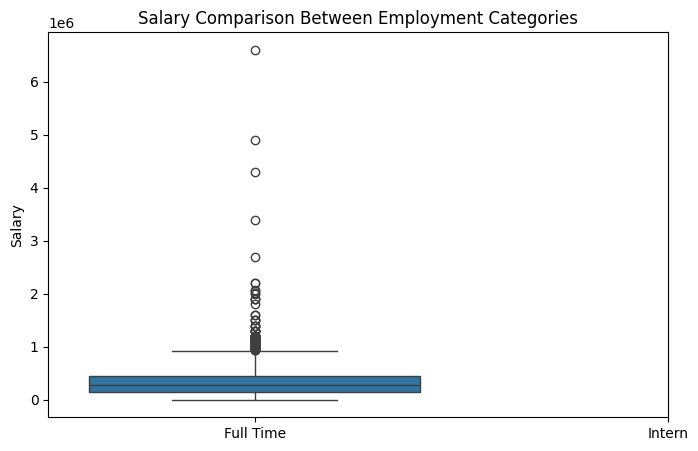

In [11]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=[
    group1,
    group2
])

plt.xticks(
    [0, 1],
    [str(groups[0]), str(groups[1])]
)

plt.title("Salary Comparison Between Employment Categories")
plt.ylabel("Salary")

plt.show()

## Scenario 3: Employee Rating Comparison

### Business Problem
A company wants to determine whether employee ratings differ between two employment categories.

### Objective
To compare average employee ratings across two employment categories.

### Hypotheses
- **H0 (Null Hypothesis):** There is no significant difference in average employee ratings between the two employment categories.
- **H1 (Alternative Hypothesis):** There is a significant difference in average employee ratings between the two employment categories.

### Statistical Test
Independent Two-Sample Welch's T-Test.

### Significance Level
α = 0.05.

### Decision Criteria
- If p-value < 0.05, reject H0.
- If p-value ≥ 0.05, fail to reject H0.

### Business Outcome
Understand whether employee ratings vary significantly across employment categories.

In [12]:
rating_group1 = df[
    df['Employment Status'] == groups[0]
]['Rating'].dropna()

rating_group2 = df[
    df['Employment Status'] == groups[1]
]['Rating'].dropna()

In [13]:
t_stat, p_value = stats.ttest_ind(
    rating_group1,
    rating_group2,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject Null Hypothesis")
    print("Employee ratings differ significantly.")
else:
    print("Fail to Reject Null Hypothesis")
    print("No significant rating difference detected.")

T-statistic: -5.353236083102277
P-value: 9.405150443450413e-08
Reject Null Hypothesis
Employee ratings differ significantly.


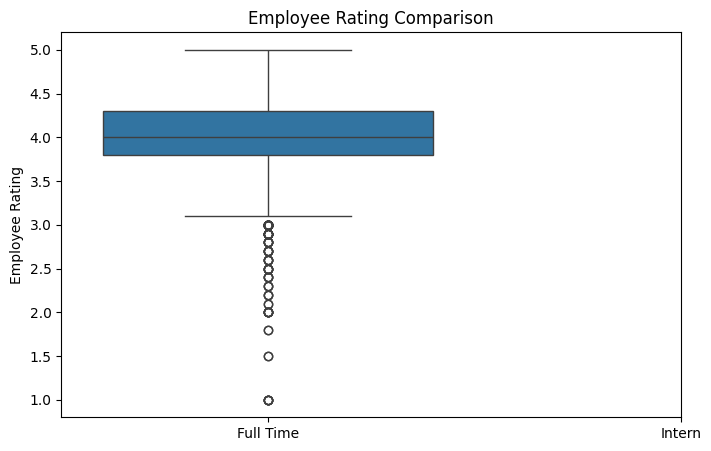

In [14]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=[
    rating_group1,
    rating_group2
])

plt.xticks(
    [0, 1],
    [str(groups[0]), str(groups[1])]
)

plt.title("Employee Rating Comparison")
plt.ylabel("Employee Rating")

plt.show()